# AI651 PA2 — Question 2: Motion or Memory?
ConvLSTM on Moving MNIST, stress-tested with mirror, rotation and speed-up.

**Kaggle settings:** Accelerator **GPU (T4 or P100)**, Internet **On** (for the one-time Moving MNIST download).

**How to run**
1. Set `SMOKE = True` and *Run All* once (≈2 min). This checks that every cell works on a tiny subset.
2. Set `SMOKE = False`, then run the sections **in order**. Stop at the two STOP cells (Q2.5 and Q2.11), write your prediction, **commit it to GitHub**, then continue.
3. Trained weights go to `/kaggle/working/checkpoints`. If a checkpoint exists, training is skipped, so a crashed session can resume. Download `/kaggle/working` (checkpoints, figures, gifs, results) at the end.

Sections follow the handout: 1 Setup (Table 1, Figure 1) → 2 Baseline (Table 2, Figure 2) → 3 Testing (Tables 3–4, Figures 3–5) → 4 What can data fix (Table 5) → 5 Final model (Table 6, Figure 6).

In [1]:
# ---------------- configuration ----------------
SMOKE = False            # True: tiny quick run to test the pipeline. False: the real experiments.

import os, time, json, math, random, glob
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK = '/kaggle/working' if os.path.isdir('/kaggle/working') else os.path.abspath('q2_work')
TAG = 'smoke' if SMOKE else 'full'
CKPT, FIGS, GIFS, RES = (f'{WORK}/{d}_{TAG}' if SMOKE else f'{WORK}/{d}' for d in ('checkpoints', 'figures', 'gifs', 'results'))
for d in (CKPT, FIGS, GIFS, RES): os.makedirs(d, exist_ok=True)

EPOCHS = 1 if SMOKE else 30
CAND_EPOCHS = 1 if SMOKE else 5        # short runs used only to choose model D on the validation split
BATCH, LR, SEEDS = 32, 1e-3, (0, 1)

TRAIN_IDX = np.arange(0, 8000)
VAL_IDX   = np.arange(8000, 9000)
TEST_IDX  = np.arange(9000, 10000)
if SMOKE:
    TRAIN_IDX, VAL_IDX, TEST_IDX = TRAIN_IDX[:256], VAL_IDX[:64], TEST_IDX[:64]

HW = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'
print('device:', DEVICE, '|', HW, '| torch', torch.__version__, '| mode:', TAG, '| work dir:', WORK)

device: cuda | Tesla T4 | torch 2.11.0+cu128 | mode: full | work dir: /kaggle/working


## 1. Setup
### Data

In [2]:
from torchvision.datasets import MovingMNIST

def load_moving_mnist():
    # Prefer a copy attached as a Kaggle dataset; otherwise download with torchvision.
    hits = glob.glob('/kaggle/input/**/mnist_test_seq.npy', recursive=True)
    if hits:
        arr = np.load(hits[0])                      # (20, 10000, 64, 64) uint8
        return torch.from_numpy(arr).permute(1, 0, 2, 3).contiguous()
    ds = MovingMNIST(root=f'{WORK}/data', split=None, download=True)
    data = ds.data                                  # (10000, 20, 1, 64, 64) uint8
    return data[:, :, 0].contiguous()

DATA_U8 = load_moving_mnist()                       # (10000, 20, 64, 64) uint8, frame f is index f-1
assert DATA_U8.shape == (10000, 20, 64, 64) and DATA_U8.dtype == torch.uint8, DATA_U8.shape
DATA_GPU = DATA_U8.to(DEVICE)                       # 82 MB; converted to float32/255 per batch
print('videos:', DATA_U8.shape)

100%|██████████| 819M/819M [00:21<00:00, 37.4MB/s] 


videos: torch.Size([10000, 20, 64, 64])


### Transformations, windows and the symmetry group

In [3]:
def mirror(x):            return x.flip(-1)                               # (Mx)[i,j] = x[i, 63-j]
def rotate(x, a=1):       return torch.rot90(x, k=a % 4, dims=(-2, -1))   # R^a, anticlockwise
def apply_g(x, a, m):     return mirror(rotate(x, a)) if m else rotate(x, a)      # M R^a: rotate first, then mirror
def apply_g_inv(x, a, m): return apply_g(x, a, m) if m else rotate(x, -a)         # (M R^a) self-inverse, (R^a)^-1 = R^-a
G = [(a, m) for m in (0, 1) for a in range(4)]                            # index 0 is the identity

def apply_g_batch(x, gs):
    # x: [B, ...]; gs: [B] indices into G. Applies a (possibly different) symmetry to each sample.
    out = x.clone()
    for gi, (a, m) in enumerate(G):
        sel = (gs == gi).nonzero(as_tuple=True)[0]
        if len(sel): out[sel] = apply_g(x[sel], a, m)
    return out

def window_frames(t, k):
    # 1-based frame numbers of a window at speed k starting at frame t (Eq. 2); only existing targets kept.
    inputs  = [t + j * k for j in range(5)]
    targets = [t + j * k for j in range(5, 10) if t + j * k <= 20]
    return inputs, targets

def make_window(video, t, k=1):
    # video: [20, ...] with frame f at index f-1
    inp, tgt = window_frames(t, k)
    return video[[f - 1 for f in inp]], video[[f - 1 for f in tgt]]

T_MAX = {1: 14, 2: 8, 3: 2}   # speed-augmented starts: 5 inputs and >= 2 targets exist
assert all(max(t for t in range(1, 21) if t + 6 * k <= 20) == T_MAX[k] for k in (1, 2, 3))

def batch_windows(vids, ks, ts):
    # Vectorised windows. vids/ks/ts: LongTensors [B] on DEVICE. Returns X [B,5,1,64,64], Y [B,5,1,64,64], avail [B,5].
    j = torch.arange(10, device=DEVICE)
    frames = ts[:, None] + j[None] * ks[:, None]
    avail = (frames[:, 5:] <= 20).float()
    clip = DATA_GPU[vids[:, None], frames.clamp(max=20) - 1].float().div_(255).unsqueeze(2)
    return clip[:, :5], clip[:, 5:], avail

### Table 1 — checking the code

In [4]:
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1

def bright(v): return tuple(int(i) for i in (v == v.max()).nonzero()[0][[0, 2, 3]])
def frames_of(k):
    v = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64)
    X, Y = make_window(v, 1, k)
    f = lambda z: ', '.join(str(int(a)) for a in z[:, 0, 0, 0])
    return f'{f(X)} / {f(Y)}'

checks = [
    ('(a) max|M(M(x)) - x|',      (mirror(mirror(x)) - x).abs().max().item(),               torch.equal(mirror(mirror(x)), x)),
    ('(b) max|R^4(x) - x|',       (rotate(x, 4) - x).abs().max().item(),                    torch.equal(rotate(rotate(rotate(rotate(x)))), x)),
    ('(c) max|MRM(x) - R^-1(x)|', (mirror(rotate(mirror(x))) - rotate(x, -1)).abs().max().item(), torch.equal(mirror(rotate(mirror(x))), rotate(x, -1))),
    ('(d) bright pixel of M(p)',  bright(mirror(p)), None),
    ('(e) bright pixel of R(p)',  bright(rotate(p)), None),
    ('(f) 1x input / target',     frames_of(1), None),
    ('(g) 2x input / target',     frames_of(2), None),
    ('(h) 3x input / target',     frames_of(3), None),
]
expected = [0, 0, 0, (7, 10, 43), (7, 43, 10), '1, 2, 3, 4, 5 / 6, 7, 8, 9, 10',
            '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19', '1, 4, 7, 10, 13 / 16, 19']
print(f'{"Check":30s} {"Expected":40s} Yours')
for (name, val, eq), exp in zip(checks, expected):
    extra = f'   torch.equal={eq}' if eq is not None else ''
    print(f'{name:30s} {str(exp):40s} {val}{extra}')
    assert val == exp, f'MISMATCH in {name}: fix before continuing'
for gi, (a, m) in enumerate(G):   # every element of G is undone by its inverse
    assert torch.equal(apply_g_inv(apply_g(x, a, m), a, m), x)
print('\nAll Table 1 checks pass.')

Check                          Expected                                 Yours
(a) max|M(M(x)) - x|           0                                        0.0   torch.equal=True
(b) max|R^4(x) - x|            0                                        0.0   torch.equal=True
(c) max|MRM(x) - R^-1(x)|      0                                        0.0   torch.equal=True
(d) bright pixel of M(p)       (7, 10, 43)                              (7, 10, 43)
(e) bright pixel of R(p)       (7, 43, 10)                              (7, 43, 10)
(f) 1x input / target          1, 2, 3, 4, 5 / 6, 7, 8, 9, 10           1, 2, 3, 4, 5 / 6, 7, 8, 9, 10
(g) 2x input / target          1, 3, 5, 7, 9 / 11, 13, 15, 17, 19       1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h) 3x input / target          1, 4, 7, 10, 13 / 16, 19                 1, 4, 7, 10, 13 / 16, 19

All Table 1 checks pass.


### Figure 1 — is the training data already symmetric?
Farneback flow on the first 50 training videos (950 frame pairs), exactly the settings in the handout.

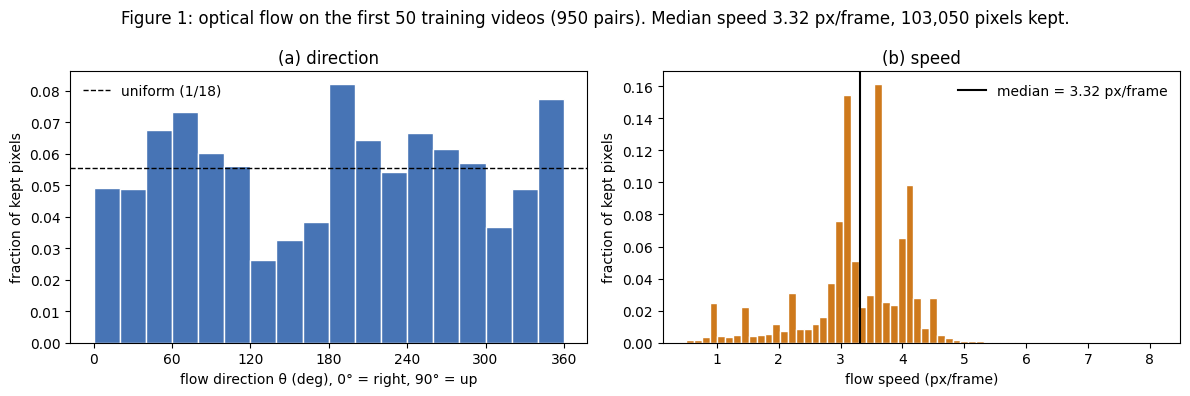

median speed 3.32 px/frame -> 2x ~ 6.64, 3x ~ 9.95 px/frame; kept pixels 103,050


In [5]:
import cv2
angles, speeds = [], []
for v in range(50):
    vid = DATA_U8[v].numpy()                         # uint8 = frames on [0,1] x 255
    for s in range(19):
        prev, nxt = vid[s], vid[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.hypot(dx, dy)
        keep = (prev > 51) & (nxt > 51) & (mag > 0.5)    # > 0.2 on the [0,1] scale in both frames
        angles.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360)
        speeds.append(mag[keep])
angles, speeds = np.concatenate(angles), np.concatenate(speeds)
n_kept, med_speed = len(speeds), float(np.median(speeds))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
w = np.full(n_kept, 1 / n_kept)
ax[0].hist(angles, bins=np.arange(0, 361, 20), weights=w, color='#4774b5', edgecolor='white')
ax[0].axhline(1 / 18, color='k', ls='--', lw=1, label='uniform (1/18)')
ax[0].set(xlabel='flow direction θ (deg), 0° = right, 90° = up', ylabel='fraction of kept pixels', title='(a) direction', xticks=range(0, 361, 60))
ax[0].legend(frameon=False)
ax[1].hist(speeds, bins=60, weights=w, color='#ce791c', edgecolor='white')
ax[1].axvline(med_speed, color='k', lw=1.5, label=f'median = {med_speed:.3g} px/frame')
ax[1].set(xlabel='flow speed (px/frame)', ylabel='fraction of kept pixels', title='(b) speed')
ax[1].legend(frameon=False)
fig.suptitle(f'Figure 1: optical flow on the first 50 training videos (950 pairs). Median speed {med_speed:.3g} px/frame, {n_kept:,} pixels kept.')
fig.tight_layout(); fig.savefig(f'{FIGS}/figure1_flow.png', dpi=150); plt.show()
print(f'median speed {med_speed:.3g} px/frame -> 2x ~ {2*med_speed:.3g}, 3x ~ {3*med_speed:.3g} px/frame; kept pixels {n_kept:,}')
json.dump({'median_speed': med_speed, 'n_kept': int(n_kept)}, open(f'{RES}/figure1.json', 'w'))

**Q2.1 / Q2.2** — answer in the report from Figure 1:
* Mirroring maps θ → 180° − θ; rotating by 90° maps θ → θ + 90°. If the histogram is roughly flat (close to 1/18 in every bin), mirrored and rotated *trajectories* are already familiar; the *digits* are not.
* Speed: 2× and 3× multiply the per-frame displacement by 2 and 3.

## 2. Baseline: ConvLSTM (model A)

In [6]:
class ConvLSTMCell(nn.Module):
    # Eq. (3)-(4): one convolution on [u, h_prev] gives all four gates; no peepholes.
    def __init__(self, cin, hid=64, k=3, dil=1):
        super().__init__()
        self.hid = hid
        self.conv = nn.Conv2d(cin + hid, 4 * hid, k, stride=1, padding=dil * (k - 1) // 2, dilation=dil, bias=True)
    def forward(self, u, h, c):
        i, f, o, g = self.conv(torch.cat([u, h], 1)).chunk(4, 1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class Forecaster(nn.Module):
    # Model A = Forecaster(patch=4, k=3, dil=(1, 1)). Model D changes patch/k/dil only.
    def __init__(self, patch=4, hid=64, k=3, dil=(1, 1)):
        super().__init__()
        self.patch, self.hid, self.cfg = patch, hid, dict(patch=patch, hid=hid, k=k, dil=tuple(dil))
        cin = patch * patch
        self.cell1 = ConvLSTMCell(cin, hid, k, dil[0])
        self.cell2 = ConvLSTMCell(hid, hid, k, dil[1])
        self.out = nn.Conv2d(hid, cin, 1, bias=True)
    def init_state(self, B, device):
        s = 64 // self.patch
        z = torch.zeros(B, self.hid, s, s, device=device)
        return [z, z.clone(), z.clone(), z.clone()]
    def step(self, u, state):
        h1, c1, h2, c2 = state
        h1, c1 = self.cell1(F.pixel_unshuffle(u, self.patch), h1, c1)
        h2, c2 = self.cell2(h1, h2, c2)
        pred = torch.sigmoid(F.pixel_shuffle(self.out(h2), self.patch))
        return pred, [h1, c1, h2, c2]
    def forward(self, X):
        # X: [B,5,1,64,64]. 9-step rollout, no teacher forcing; outputs of steps 5..9 are Y_hat.
        state = self.init_state(X.shape[0], X.device)
        outs, pred = [], None
        for tau in range(9):
            u = X[:, tau] if tau < 5 else pred
            pred, state = self.step(u, state)
            if tau >= 4: outs.append(pred)
        return torch.stack(outs, 1)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
MODEL_A_CFG = dict(patch=4, k=3, dil=(1, 1))
assert n_params(Forecaster(**MODEL_A_CFG)) == 480_784, n_params(Forecaster(**MODEL_A_CFG))
print('model A parameters:', n_params(Forecaster(**MODEL_A_CFG)))

class Blank(nn.Module):
    def forward(self, X): return torch.zeros_like(X)
class CopyLast(nn.Module):
    def forward(self, X): return X[:, -1:].expand(-1, 5, -1, -1, -1).clone()
class Symmetrised(nn.Module):
    # Eq. (7): f_bar(X) = 1/8 sum_g g^-1(f(g(X)))
    def __init__(self, base): super().__init__(); self.base = base
    def forward(self, X):
        return torch.stack([apply_g_inv(self.base(apply_g(X, a, m)), a, m) for a, m in G]).mean(0)

model A parameters: 480784


### Reach (supports Q2.3 and Q2.12)
Measured, not just reasoned: take one step from random states, and find which folded cells of the input
$u_\tau$ and of the previous states $h^{(1)}_{\tau-1}, h^{(2)}_{\tau-1}$ have a non-zero gradient on the prediction at the centre cell.
Reach = largest centre-to-centre cell distance × patch size (the patch width itself is not added).

In [7]:
def one_step_reach(model):
    model = model.cpu().double()
    P, s = model.patch, 64 // model.patch
    torch.manual_seed(0)
    u = torch.rand(1, 1, 64, 64, dtype=torch.double, requires_grad=True)
    st = [torch.randn(1, model.hid, s, s, dtype=torch.double, requires_grad=True) for _ in range(4)]
    pred, _ = model.step(u, st)
    cc = s // 2
    pred[..., cc * P:(cc + 1) * P, cc * P:(cc + 1) * P].sum().backward()
    def reach(grad_cells):            # grad_cells: [C, s, s]
        nz = (grad_cells.abs().sum(0) > 0).nonzero()
        d = (nz - cc).abs().max(1).values.max().item()       # along-axis (Chebyshev) cell distance
        return d, d * P
    out = {'input u_tau': reach(F.pixel_unshuffle(u.grad, P)[0]),
           'h1_prev': reach(st[0].grad[0]), 'h2_prev': reach(st[2].grad[0])}
    model.float()
    return out, max(v[1] for v in out.values())

for name, cfg in [('A', MODEL_A_CFG)]:
    paths, r = one_step_reach(Forecaster(**cfg))
    print(name, {k: f'{c} cells = {px} px' for k, (c, px) in paths.items()}, '-> reach', r, 'px')

A {'input u_tau': '2 cells = 8 px', 'h1_prev': '2 cells = 8 px', 'h2_prev': '1 cells = 4 px'} -> reach 8 px


### Training and evaluation utilities

In [8]:
def masked_mse(pred, Y, avail):
    per = ((pred - Y) ** 2).mean(dim=(2, 3, 4))               # [B,5]: mean over pixels of each frame
    return ((per * avail).sum(1) / avail.sum(1)).mean()      # mean over available frames, then over videos

def sample_epoch(gen, speed_aug, sym_aug):
    n = len(TRAIN_IDX)
    vids = torch.from_numpy(TRAIN_IDX)[torch.randperm(n, generator=gen)]
    ks = torch.randint(1, 4, (n,), generator=gen) if speed_aug else torch.ones(n, dtype=torch.long)
    tmax = torch.tensor([0, T_MAX[1], T_MAX[2], T_MAX[3]])[ks] if speed_aug else torch.full((n,), 11)
    ts = 1 + (torch.rand(n, generator=gen) * tmax).long()    # uniform over 1..tmax
    gs = torch.randint(0, 8, (n,), generator=gen) if sym_aug else torch.zeros(n, dtype=torch.long)
    return vids, ks, ts, gs

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

def train(name, cfg, seed, speed_aug=False, sym_aug=False, epochs=None, ckpt_dir=None):
    epochs = epochs or EPOCHS
    path = f'{ckpt_dir or CKPT}/{name}_s{seed}.pt'
    if os.path.exists(path):
        saved = torch.load(path, map_location='cpu')
        model = Forecaster(**saved['cfg']).to(DEVICE); model.load_state_dict(saved['state']); model.eval()
        print(f'loaded {path}  (epoch time {np.mean(saved["epoch_times"]):.1f}s)')
        return model, saved
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = Forecaster(**cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    times, losses = [], []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.perf_counter(); tot = 0.0
        vids, ks, ts, gs = sample_epoch(gen, speed_aug, sym_aug)
        for i in range(0, len(vids), BATCH):
            sl = slice(i, i + BATCH)
            X, Y, avail = batch_windows(vids[sl].to(DEVICE), ks[sl].to(DEVICE), ts[sl].to(DEVICE))
            if sym_aug:
                g = gs[sl].to(DEVICE); X, Y = apply_g_batch(X, g), apply_g_batch(Y, g)
            loss = masked_mse(model(X), Y, avail)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item() * len(X)
        sync(); times.append(time.perf_counter() - t0); losses.append(tot / len(vids))
        if ep % 5 == 4 or ep == epochs - 1:
            print(f'{name} s{seed} epoch {ep+1}/{epochs}  train loss {losses[-1]:.5f}  {times[-1]:.1f}s/epoch')
    model.eval()
    saved = dict(state=model.state_dict(), cfg=cfg, seed=seed, speed_aug=speed_aug, sym_aug=sym_aug,
                 epoch_times=times, losses=losses, hardware=HW, epochs=epochs)
    torch.save(saved, path)
    return model, saved

# ---------- evaluation ----------
def split_window(idx, k=1, t=1):
    vids = torch.as_tensor(idx, device=DEVICE)
    n = len(vids)
    return batch_windows(vids, torch.full((n,), k, device=DEVICE), torch.full((n,), t, device=DEVICE))

@torch.no_grad()
def predict(model, X, bs=BATCH):
    model.eval()
    return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])

def per_video(a, b):          # [N,5] per-horizon MSE over pixels
    return ((a - b) ** 2).mean(dim=(2, 3, 4))

def masked_mean(per, avail, H):   # mean over the first H horizons (available ones), then over videos
    m = avail[:, :H]
    return ((per[:, :H] * m).sum(1) / m.sum(1)).mean().item()

@torch.no_grad()
def evaluate(model, idx=TEST_IDX, transforms=True, speeds=True):
    r = {}
    X, Y, av = split_window(idx, 1)
    fX = predict(model, X)
    per = per_video(fX, Y)
    r['MSE_h'] = per.mean(0).tolist()
    r['E5_1x'] = masked_mean(per, av, 5); r['E2_1x'] = masked_mean(per, av, 2)
    pv = {'E5': per.mean(1).cpu()}
    if transforms:
        for T, (a, m) in (('M', (0, 1)), ('R', (1, 0))):
            fTX = predict(model, apply_g(X, a, m))
            C = per_video(fTX, apply_g(fX, a, m)).mean(1); E = per_video(fTX, apply_g(Y, a, m)).mean(1)
            r[f'C_{T}'], r[f'E_{T}'] = C.mean().item(), E.mean().item()
            pv[f'C_{T}'], pv[f'E_{T}'] = C.cpu(), E.cpu()
    if speeds:
        for k in (2, 3):
            Xk, Yk, avk = split_window(idx, k)
            perk = per_video(predict(model, Xk), Yk)
            r[f'E2_{k}x'] = masked_mean(perk, avk, 2)
            if k == 2: r['E5_2x'] = masked_mean(perk, avk, 5)
    return r, pv

@torch.no_grad()
def inference_time(model, idx=TEST_IDX):
    X, _, _ = split_window(idx, 1)
    batches = [X[i:i + BATCH] for i in range(0, len(X), BATCH)]   # already on the device
    model.eval(); model(batches[0]); sync()                         # warm-up
    t0 = time.perf_counter()
    for b in batches: model(b)
    sync(); return time.perf_counter() - t0

def fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)): return '–'
    if isinstance(v, (int, np.integer)): return f'{v:,}'
    return f'{v:.2e}' if abs(v) < 1e-3 and v != 0 else f'{v:#.3g}'
def fmt_seeds(vals):
    return fmt(float(np.mean(vals))) if len(vals) == 1 else f'{fmt(float(np.mean(vals)))} ({", ".join(fmt(v) for v in vals)})'

def table(rows, cols, title):
    import pandas as pd
    df = pd.DataFrame([[r[0]] + [r[1].get(c, '–') for c in cols] for r in rows], columns=['Model'] + cols).set_index('Model')
    print(title); display(df); return df

RESULTS = {}         # RESULTS[name] = list over seeds of (metrics, per-video, saved-info)
def run_model(name, cfg, speed_aug=False, sym_aug=False):
    RESULTS[name] = []
    for seed in SEEDS:
        model, saved = train(name, cfg, seed, speed_aug, sym_aug)
        metrics, pv = evaluate(model)
        metrics['params'] = n_params(model); metrics['train_s_per_epoch'] = float(np.mean(saved['epoch_times']))
        metrics['infer_s'] = inference_time(model)
        RESULTS[name].append((metrics, pv, model))
        json.dump(metrics, open(f'{RES}/{name}_s{seed}.json', 'w'))
    return RESULTS[name]

def summarise(name, keys):
    runs = RESULTS[name]
    return {k: fmt_seeds([r[0][k] for r in runs]) if k != 'params' else fmt(runs[0][0]['params']) for k in keys}

### Train model A (2 seeds)

In [9]:
run_model('A', MODEL_A_CFG)
BLANK_R, BLANK_PV = evaluate(Blank().to(DEVICE)); COPY_R, COPY_PV = evaluate(CopyLast().to(DEVICE))
BLANK_R['params'] = COPY_R['params'] = 0
print('training hardware:', HW, '| model A time/epoch:', [round(r[0]['train_s_per_epoch'], 1) for r in RESULTS['A']], 's')

A s0 epoch 5/30  train loss 0.03529  10.2s/epoch
A s0 epoch 10/30  train loss 0.02982  10.7s/epoch
A s0 epoch 15/30  train loss 0.02763  10.6s/epoch
A s0 epoch 20/30  train loss 0.02564  10.6s/epoch
A s0 epoch 25/30  train loss 0.02388  10.6s/epoch
A s0 epoch 30/30  train loss 0.02250  10.6s/epoch
A s1 epoch 5/30  train loss 0.03753  10.5s/epoch
A s1 epoch 10/30  train loss 0.02997  10.6s/epoch
A s1 epoch 15/30  train loss 0.02672  10.6s/epoch
A s1 epoch 20/30  train loss 0.02465  10.6s/epoch
A s1 epoch 25/30  train loss 0.02295  10.6s/epoch
A s1 epoch 30/30  train loss 0.02169  10.6s/epoch
training hardware: Tesla T4 | model A time/epoch: [10.6, 10.6] s


### Table 2

In [10]:
def ref_row(r, keys): return {k: fmt(r[k]) for k in keys}
def mse_cols(r): return {f'MSE_{h+1}': r['MSE_h'][h] for h in range(5)}
cols2 = [f'MSE_{h}' for h in range(1, 6)] + ['E5_1x', 'params']
rowA = {f'MSE_{h+1}': fmt_seeds([run[0]['MSE_h'][h] for run in RESULTS['A']]) for h in range(5)}
rowA.update(summarise('A', ['E5_1x', 'params']))
rows = [('A (ConvLSTM)', rowA),
        ('Blank', {**{k: fmt(v) for k, v in mse_cols(BLANK_R).items()}, 'E5_1x': fmt(BLANK_R['E5_1x']), 'params': '0'}),
        ('Copy-last', {**{k: fmt(v) for k, v in mse_cols(COPY_R).items()}, 'E5_1x': fmt(COPY_R['E5_1x']), 'params': '0'})]
T2 = table(rows, cols2, 'Table 2: test split, 1x, t=1. Learned models: mean (seed 0, seed 1).')
T2.to_csv(f'{RES}/table2.csv')

Table 2: test split, 1x, t=1. Learned models: mean (seed 0, seed 1).


,MSE_1,MSE_2,MSE_3,MSE_4,MSE_5,E5_1x,params
Model,,,,,,,
A (ConvLSTM),"0.0172 (0.0174, 0.0169)","0.0206 (0.0210, 0.0202)","0.0228 (0.0233, 0.0223)","0.0246 (0.0250, 0.0241)","0.0262 (0.0267, 0.0258)","0.0223 (0.0227, 0.0219)","480,784"
Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Figure 2 — three test videos (one with overlapping digits)

Figure 2 test videos (position in test split): [851, 305, 419] | overlap scores [0.289 0.034 0.   ]


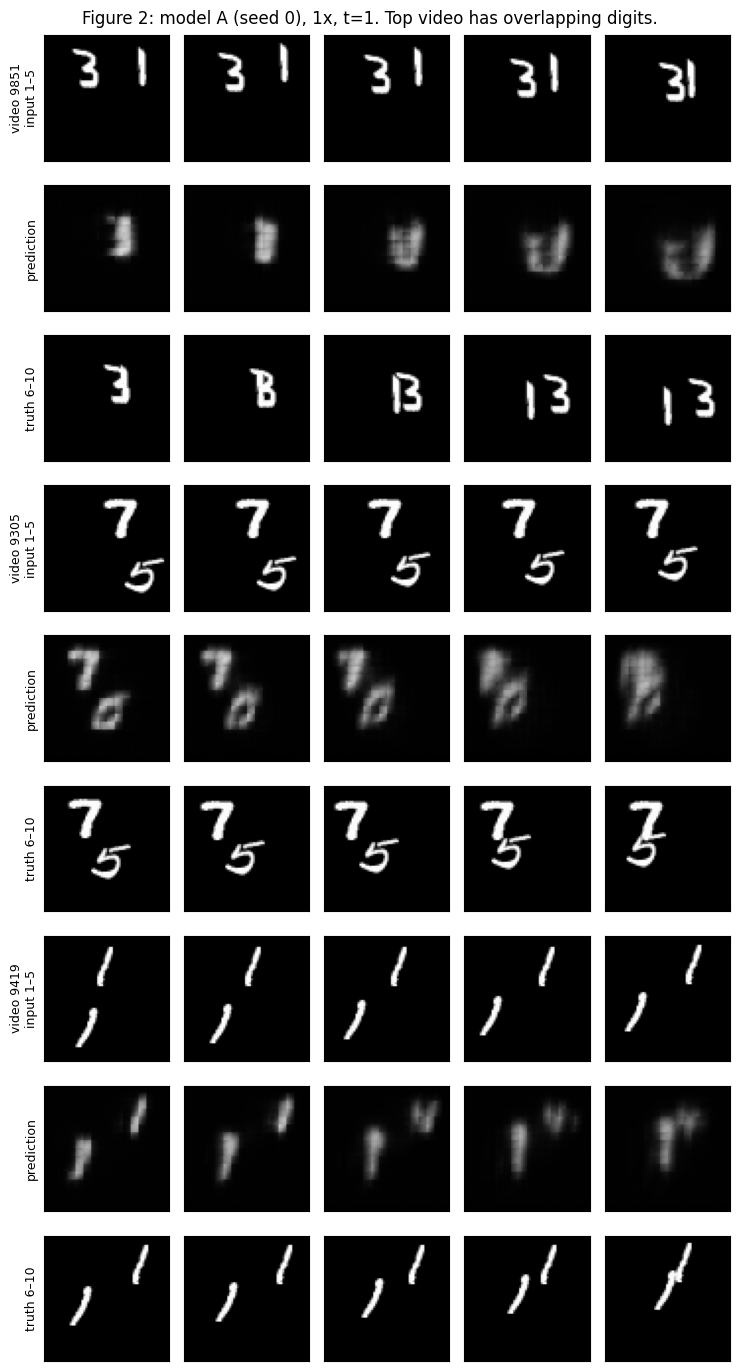

In [11]:
# Overlap heuristic: when two digits overlap, the number of bright pixels in a frame drops below the video's usual level.
bright_cnt = (DATA_U8[TEST_IDX] > 51).flatten(2).sum(-1).float()          # [N,20]
def overlap_score(frames):                                                  # frames: 1-based frame numbers
    return (1 - bright_cnt[:, [f - 1 for f in frames]].min(1).values / bright_cnt.max(1).values).numpy()
ov = overlap_score(range(6, 11))
order = np.argsort(ov)
FIG2_VIDS = [int(order[-1]), int(order[len(order) // 2]), int(order[0])]    # most overlap, typical, least overlap
print('Figure 2 test videos (position in test split):', FIG2_VIDS, '| overlap scores', np.round(ov[FIG2_VIDS], 3))

def show_frames(axs, frames, label):
    for ax, f in zip(axs, frames):
        ax.imshow(f.squeeze().cpu(), cmap='gray', vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
    axs[0].set_ylabel(label, fontsize=9)

modelA0 = RESULTS['A'][0][2]
X, Y, _ = split_window(TEST_IDX[FIG2_VIDS], 1)
P = predict(modelA0, X)
fig, axs = plt.subplots(9, 5, figsize=(7.5, 14))
for r, v in enumerate(FIG2_VIDS):
    show_frames(axs[3*r], X[r], f'video {TEST_IDX[v]}\ninput 1–5')
    show_frames(axs[3*r+1], P[r], 'prediction')
    show_frames(axs[3*r+2], Y[r], 'truth 6–10')
fig.suptitle('Figure 2: model A (seed 0), 1x, t=1. Top video has overlapping digits.')
fig.tight_layout(); fig.savefig(f'{FIGS}/figure2.png', dpi=130); plt.show()

## Model A should roughly pass the mirror test, because mirrored trajectories are common in training (Figure 1a), but the digits will look unfamiliar, so expect some blur. Rotation should be harder for the same reason (rotated digits look even less like training digits). Given a reach of about 8 px per step and a median speed of a few px/frame, 2× should be borderline and 3× should break down.


## 3. Testing the baseline
### Table 3 — mirror and rotation

In [ ]:
cols3 = ['E5_1x', 'C_M', 'E_M', 'C_R', 'E_R']
rows = [('A', summarise('A', cols3)), ('Blank', ref_row(BLANK_R, cols3)), ('Copy-last', ref_row(COPY_R, cols3))]
T3 = table(rows, cols3, 'Table 3: test split, 1x, t=1.'); T3.to_csv(f'{RES}/table3.csv')

### Figure 3 + GIFs, Figure 4

In [ ]:
from PIL import Image
TS = {'M': (0, 1), 'R': (1, 0)}

def fig3_panel(model, v, Tn, title, fname):
    a, m = TS[Tn]
    X, Y, _ = split_window(TEST_IDX[[v]], 1)
    fX = predict(model, X); TX = apply_g(X, a, m)
    rows = [(X, fX, 'X | f(X)'), (TX, apply_g(Y, a, m), f'{Tn}(X) | {Tn}(Y)'),
            (TX, predict(model, TX), f'{Tn}(X) | f({Tn}(X))'), (TX, apply_g(fX, a, m), f'{Tn}(X) | {Tn}(f(X))')]
    fig, axs = plt.subplots(4, 10, figsize=(13, 5.6))
    for r, (left, right, lab) in enumerate(rows):
        show_frames(axs[r], torch.cat([left[0], right[0]]), lab)
    for c in range(10): axs[0, c].set_title(f'{"in" if c < 5 else "h="}{c+1 if c < 5 else c-4}', fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(f'{FIGS}/{fname}.png', dpi=120); plt.show()
    # GIF: one frame per forecast horizon, same four rows (last input | horizon h)
    frames = []
    for h in range(5):
        g, gx = plt.subplots(4, 2, figsize=(3.2, 6.2))
        for r, (left, right, lab) in enumerate(rows):
            for c, img in enumerate((left[0, -1], right[0, h])):
                gx[r, c].imshow(img.squeeze().cpu(), cmap='gray', vmin=0, vmax=1); gx[r, c].axis('off')
            gx[r, 0].set_title(lab, fontsize=7, loc='left')
        g.suptitle(f'{fname}  horizon h={h+1}', fontsize=8); g.tight_layout(); g.canvas.draw()
        frames.append(Image.fromarray(np.asarray(g.canvas.buffer_rgba())[..., :3])); plt.close(g)
    gif = f'{GIFS}/{fname}.gif'
    frames[0].save(gif, save_all=True, append_images=frames[1:], duration=700, loop=0)
    return gif

pvA0 = RESULTS['A'][0][1]
FIG3 = {T: [int(i) for i in torch.argsort(pvA0[f'C_{T}'], descending=True)[:2]] for T in ('M', 'R')}
print('Figure 3 videos (position in test split):', FIG3)
FIG3_GIFS = [fig3_panel(modelA0, v, T, f'Figure 3: model A s0, T={T}, test video {TEST_IDX[v]} (C_{T} = {pvA0[f"C_{T}"][v]:.3g})', f'figure3_A_{T}_{TEST_IDX[v]}')
             for T in ('M', 'R') for v in FIG3[T]]
print('GIFs:', FIG3_GIFS)

def figure4(pv, marks, tag, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for i, T in enumerate(('M', 'R')):
        ax[i].hist(pv[f'C_{T}'].numpy(), bins=50, color='#4774b5')
        for v in marks[T]:
            ax[i].axvline(pv[f'C_{T}'][v], color='#c44963', ls='--'); ax[i].text(pv[f'C_{T}'][v], ax[i].get_ylim()[1]*.9, f' {TEST_IDX[v]}', color='#c44963', fontsize=8)
        ax[i].set(xlabel=f'per-video C_{T}', ylabel='videos', title=f'C_{T}, {tag}')
    fig.suptitle(f'Figure 4: per-video consistency gaps, {tag}; dashed = Figure 3 videos'); fig.tight_layout()
    fig.savefig(f'{FIGS}/{fname}.png', dpi=130); plt.show()
figure4(pvA0, FIG3, 'model A seed 0', 'figure4')

### Table 4 and Figure 5 — faster motion

In [ ]:
cols4 = ['E2_1x', 'E2_2x', 'E2_3x', 'E5_1x', 'E5_2x']
rows = [('A', summarise('A', cols4)), ('Copy-last', ref_row(COPY_R, cols4))]
T4 = table(rows, cols4, 'Table 4: test split, t=1. E2 compares across speeds; E5 only where 5 targets exist.')
T4.to_csv(f'{RES}/table4.csv')

shown = sorted({f for k in (1, 2, 3) for f in window_frames(1, k)[0] + window_frames(1, k)[1][:2]})
FIG5_VID = int(np.argmin(overlap_score(shown)))
print('Figure 5 video (position in test split):', FIG5_VID, 'test video', TEST_IDX[FIG5_VID])

def figure5(model, v, title, fname):
    fig, axs = plt.subplots(3, 9, figsize=(13, 4.6))
    for r, k in enumerate((1, 2, 3)):
        X, Y, _ = split_window(TEST_IDX[[v]], k); Pk = predict(model, X)
        inp, tgt = window_frames(1, k)
        imgs = list(X[0]) + list(Pk[0, :2]) + list(Y[0, :2])
        labs = [f'in {f}' for f in inp] + [f'pred {f}' for f in tgt[:2]] + [f'true {f}' for f in tgt[:2]]
        for c, (img, lab) in enumerate(zip(imgs, labs)):
            axs[r, c].imshow(img.squeeze().cpu(), cmap='gray', vmin=0, vmax=1); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
            axs[r, c].set_title(lab, fontize=8)
        axs[r, 0].set_ylabel(f'{k}x', fontsize=11)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(f'{FIGS}/{fname}.png', dpi=130); plt.show()
figure5(modelA0, FIG5_VID, f'Figure 5: model A seed 0, test video {TEST_IDX[FIG5_VID]}, t=1', 'figure5')

## 4. What can data fix?
### Choosing model D on the validation split
Candidates (all ≤ 721,176 parameters, everything else identical to A). Each is trained briefly with speed augmentation (seed 0) and compared on **validation only**.

In [ ]:
D_CANDIDATES = {
    'D_dil2':   dict(patch=4, k=3, dil=(2, 2)),   # dilated 3x3 in both layers: same params as A
    'D_dil12':  dict(patch=4, k=3, dil=(1, 2)),   # dilation only in layer 2
    'D_patch8': dict(patch=8, k=3, dil=(1, 1)),   # 8x8 patches -> 8x8 grid, each cell = 8 px
}
cand_rows = []
os.makedirs(f'{CKPT}/candidates', exist_ok=True)
for name, cfg in D_CANDIDATES.items():
    m = Forecaster(**cfg); assert n_params(m) <= 721_176
    _, r = one_step_reach(m)
    model, saved = train(name, cfg, 0, speed_aug=True, epochs=CAND_EPOCHS, ckpt_dir=f'{CKPT}/candidates')
    met, _ = evaluate(model, idx=VAL_IDX, transforms=False)
    cand_rows.append((name, {'params': fmt(n_params(m)), 'reach_px': str(r), 'val_E5_1x': fmt(met['E5_1x']),
                             'val_E2_1x': fmt(met['E2_1x']), 'val_E2_2x': fmt(met['E2_2x']), 'val_E2_3x': fmt(met['E2_3x'])}))
paths, rA = one_step_reach(Forecaster(**MODEL_A_CFG))
print('model A reach:', rA, 'px')
TD = table(cand_rows, ['params', 'reach_px', 'val_E5_1x', 'val_E2_1x', 'val_E2_2x', 'val_E2_3x'],
           f'Model D candidates: validation split, {CAND_EPOCHS} epochs, seed 0')
TD.to_csv(f'{RES}/model_D_candidates.csv')

In [ ]:
# Pick D from the validation table above (lowest validation E2 at 3x, ties -> lower 1x error). Edit if you prefer another.
D_NAME = min(cand_rows, key=lambda r: (float(r[1]['val_E2_3x']), float(r[1]['val_E5_1x'])))[0]
MODEL_D_CFG = D_CANDIDATES[D_NAME]
paths, rD = one_step_reach(Forecaster(**MODEL_D_CFG))
print('chosen D:', D_NAME, MODEL_D_CFG, '| params', n_params(Forecaster(**MODEL_D_CFG)))
print('reach paths:', {k: f'{c} cells = {px} px' for k, (c, px) in paths.items()}, '-> D reach', rD, 'px vs A', rA, 'px')
assert rD > rA

### Train B, C, D (and optional D+B)

In [ ]:
TRAIN_DB = True     # optional model D+B; set False to save ~15 GPU-minutes
run_model('B', MODEL_A_CFG, speed_aug=False, sym_aug=True)
run_model('C', MODEL_A_CFG, speed_aug=True,  sym_aug=False)
run_model('D', MODEL_D_CFG, speed_aug=True,  sym_aug=False)
if TRAIN_DB: run_model('D+B', MODEL_D_CFG, speed_aug=True, sym_aug=True)

### Table 5

In [ ]:
cols5 = ['E5_1x', 'C_M', 'E_M', 'C_R', 'E_R', 'E2_1x', 'E2_2x', 'E2_3x', 'params', 'train_s_per_epoch', 'infer_s']
names5 = ['A', 'B', 'C', 'D'] + (['D+B'] if 'D+B' in RESULTS else [])
T5 = table([(n, summarise(n, cols5)) for n in names5], cols5,
           f'Table 5: test split, t=1; mean (seed 0, seed 1). Times in seconds on {HW}.')
T5.to_csv(f'{RES}/table5.csv')

## 5. The final model
Symmetrised forecasters need no retraining. $C_M = C_R = 0$ exactly because $\bar f(T X)$ averages over the coset $G T = G$, so it equals $T\bar f(X)$; numerically it should be ~1e-15 or smaller (float32 rounding).

In [ ]:
FINAL_BASE = 'D'     # change to 'D+B' if Table 5 supports it, and say why in the report
SYM = {}
for base in dict.fromkeys(['B', 'D', FINAL_BASE]):
    name = f'sym-{base}'; RESULTS[name] = []
    for seed_i, (met_b, pv_b, model_b) in enumerate(RESULTS[base]):
        sm = Symmetrised(model_b).eval()
        met, pv = evaluate(sm)
        met['params'] = n_params(model_b); met['train_s_per_epoch'] = met_b['train_s_per_epoch']; met['infer_s'] = inference_time(sm)
        RESULTS[name].append((met, pv, sm))
        json.dump(met, open(f'{RES}/{name}_s{SEEDS[seed_i]}.json', 'w'))

# Table 6: C_M and C_R in scientific notation
def sci_seeds(vals): return f'{np.mean(vals):.2e} ({", ".join(f"{v:.2e}" for v in vals)})'
rows = []
for n in dict.fromkeys(['sym-B', 'sym-D', f'sym-{FINAL_BASE}']):
    row = summarise(n, cols5)
    for T in ('M', 'R'): row[f'C_{T}'] = sci_seeds([r[0][f'C_{T}'] for r in RESULTS[n]])
    rows.append((n + (' (final)' if n == f'sym-{FINAL_BASE}' else ''), row))
T6 = table(rows, cols5, f'Table 6: symmetrised models, test split. Training time = underlying model; inference includes all 8 passes.')
T6.to_csv(f'{RES}/table6.csv')

### Figure 6 — final model on the same videos

In [ ]:
final0 = RESULTS[f'sym-{FINAL_BASE}'][0][2]
FIG6_GIFS = [fig3_panel(final0, v, T, f'Figure 6a: final model (sym-{FINAL_BASE}, seed 0), T={T}, test video {TEST_IDX[v]}', f'figure6a_final_{T}_{TEST_IDX[v]}')
             for T in ('M', 'R') for v in FIG3[T]]
print('GIFs:', FIG6_GIFS)
figure5(final0, FIG5_VID, f'Figure 6b: final model (sym-{FINAL_BASE}, seed 0), test video {TEST_IDX[FIG5_VID]}, t=1', 'figure6b')

### Save everything

In [ ]:
summary = {n: [r[0] for r in runs] for n, runs in RESULTS.items()}
summary['Blank'], summary['Copy-last'] = BLANK_R, COPY_R
summary['meta'] = dict(hardware=HW, torch=torch.__version__, epochs=EPOCHS, smoke=SMOKE, D=D_NAME, D_cfg=MODEL_D_CFG,
                       reach_A_px=rA, reach_D_px=rD, fig2=FIG2_VIDS, fig3=FIG3, fig5=FIG5_VID)
json.dump(summary, open(f'{RES}/all_results.json', 'w'), indent=1, default=str)
os.system(f'cd {WORK} && zip -qr q2_outputs_{TAG}.zip {" ".join(os.path.basename(d) for d in (FIGS, GIFS, RES))}')
print('saved', f'{WORK}/q2_outputs_{TAG}.zip  (checkpoints are in {CKPT})')